# Week 1b — Do languages use the same K/V directions?

Week 1 showed that languages agree on **which** heads are compressible but not on **how much**.
This notebook asks the question that decides calibration transfer: do two languages put their
energy in the **same directions**?

**Setup on Kaggle.** Accelerator: **None** (CPU is enough, no GPU quota used).
Add Input → *Your Work* → the Week 1 notebook, so its `gram_<lang>.npz` files are available.

**Two metrics per (layer, KV head, rank r), for a source language A and target language B**

- **Subspace overlap**: $\lVert U_A^\top U_B \rVert_F^2 / r$, where $U$ holds the top-$r$
  eigenvectors. 1 means identical subspaces; a random subspace gives $r/d$.
- **Transfer efficiency**: energy of B captured by A's basis, divided by energy of B captured by
  its own basis at the same rank:
  $\dfrac{\operatorname{tr}(U_A^\top G_B U_A)}{\operatorname{tr}(U_B^\top G_B U_B)}$.
  This is the functional number: how much a basis calibrated on A loses when applied to B.
  It is asymmetric, so A→B and B→A are both reported.

Overlap is geometric; efficiency is what a truncation method feels. They can disagree: two
subspaces can differ in low-energy directions without hurting efficiency much.

In [1]:
import glob, itertools, os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HEAD_DIM = 128                     # Qwen3-1.7B; must match the Week 1 model
RANK_FRACS = (0.125, 0.25, 0.5)    # ranks to test, as a fraction of HEAD_DIM
SOURCE = "en"                      # calibration language highlighted in the plots
INCLUDE_JOINT = True               # also compare whole-layer subspaces (all KV heads together)

OUT_DIR = "/kaggle/working/kv_overlap" if os.path.isdir("/kaggle/working") else "./kv_overlap"
os.makedirs(OUT_DIR, exist_ok=True)

roots = ["/kaggle/input", "/kaggle/working", "."]
paths = sorted({p for r in roots if os.path.isdir(r)
                for p in glob.glob(os.path.join(r, "**", "gram_*.npz"), recursive=True)})
files = {}
for p in paths:                    # first match per language wins
    files.setdefault(re.search(r"gram_(.+)\.npz$", p).group(1), p)
assert files, "No gram_<lang>.npz found. Add the Week 1 notebook output as an input."
LANGS = list(files)
for lang, p in files.items():
    print(f"{lang}: {p}")

grams = {}
for lang, p in files.items():
    z = np.load(p)
    grams[lang] = {"K": z["K"].astype(np.float64), "V": z["V"].astype(np.float64)}
N_LAYERS, D_KV, _ = grams[LANGS[0]]["K"].shape
if D_KV % HEAD_DIM:                # smoke-test files come from a tiny model
    HEAD_DIM = 16
N_KV = D_KV // HEAD_DIM
if SOURCE not in LANGS:
    SOURCE = LANGS[0]
print(f"layers={N_LAYERS} kv_heads={N_KV} head_dim={HEAD_DIM} langs={LANGS} source={SOURCE}")

en: /kaggle/input/notebooks/macmaky/kv-catching/kv_rank_week1/gram_en.npz
es: /kaggle/input/notebooks/macmaky/kv-catching/kv_rank_week1/gram_es.npz
fi: /kaggle/input/notebooks/macmaky/kv-catching/kv_rank_week1/gram_fi.npz
qu: /kaggle/input/notebooks/macmaky/kv-catching/kv_rank_week1/gram_qu.npz
layers=28 kv_heads=8 head_dim=128 langs=['en', 'es', 'fi', 'qu'] source=en


In [2]:
def eig_desc(G):
    lam, U = np.linalg.eigh(G)
    return np.clip(lam[::-1], 0, None), U[:, ::-1]

def block(G, h):
    s = slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)
    return G[s, s]

# eigendecompositions, computed once: (lang, kind, layer, head) -> (lam, U, G); head = -1 is the joint layer
t0 = time.time()
eig = {}
for lang, kind, layer in itertools.product(LANGS, ("K", "V"), range(N_LAYERS)):
    G = grams[lang][kind][layer]
    for h in range(N_KV):
        Gh = block(G, h)
        eig[(lang, kind, layer, h)] = (*eig_desc(Gh), Gh)
    if INCLUDE_JOINT:
        eig[(lang, kind, layer, -1)] = (*eig_desc(G), G)
print(f"{len(eig)} eigendecompositions in {time.time()-t0:.0f}s")

2016 eigendecompositions in 63s


In [3]:
rows = []
for kind, layer, h in itertools.product(("K", "V"), range(N_LAYERS), list(range(N_KV)) + ([-1] if INCLUDE_JOINT else [])):
    for a, b in itertools.permutations(LANGS, 2):
        lam_a, U_a, _ = eig[(a, kind, layer, h)]
        lam_b, U_b, G_b = eig[(b, kind, layer, h)]
        d = len(lam_a)
        total_b = lam_b.sum()
        for f in RANK_FRACS:
            r = max(1, int(round(f * d)))
            Ua, Ub = U_a[:, :r], U_b[:, :r]
            overlap = float(np.linalg.norm(Ua.T @ Ub) ** 2 / r)
            own = lam_b[:r].sum()                           # = tr(Ub^T G_b Ub)
            cross = float(np.trace(Ua.T @ G_b @ Ua))
            rows.append({"kind": kind, "layer": layer, "head": h, "scope": "layer" if h < 0 else "head",
                         "source": a, "target": b, "rank_frac": f, "rank": r,
                         "overlap": overlap, "overlap_random": r / d,
                         "efficiency": cross / own,
                         "energy_own": own / total_b, "energy_cross": cross / total_b})
res = pd.DataFrame(rows)
res.to_csv(os.path.join(OUT_DIR, "subspace_transfer.csv"), index=False)
heads = res[res.scope == "head"]
summary = (heads.groupby(["kind", "rank_frac", "source", "target"])[["overlap", "efficiency"]]
           .mean().round(3))
summary.to_csv(os.path.join(OUT_DIR, "summary_by_pair.csv"))
summary

overlap  efficiency
kind rank_frac source target                     
K    0.125     en     es        0.876       0.975
                      fi        0.787       0.931
                      qu        0.749       0.939
               es     en        0.876       0.979
                      fi        0.801       0.945
...                               ...         ...
V    0.500     fi     es        0.781       0.912
                      qu        0.753       0.906
               qu     en        0.742       0.909
                      es        0.745       0.913
                      fi        0.753       0.893

[72 rows x 2 columns]

## Source × target matrices

Mean over all heads and layers. Rows are the calibration language, columns the target.
The diagonal is 1 by construction. Read the off-diagonal: how much is lost when the
basis comes from another language.

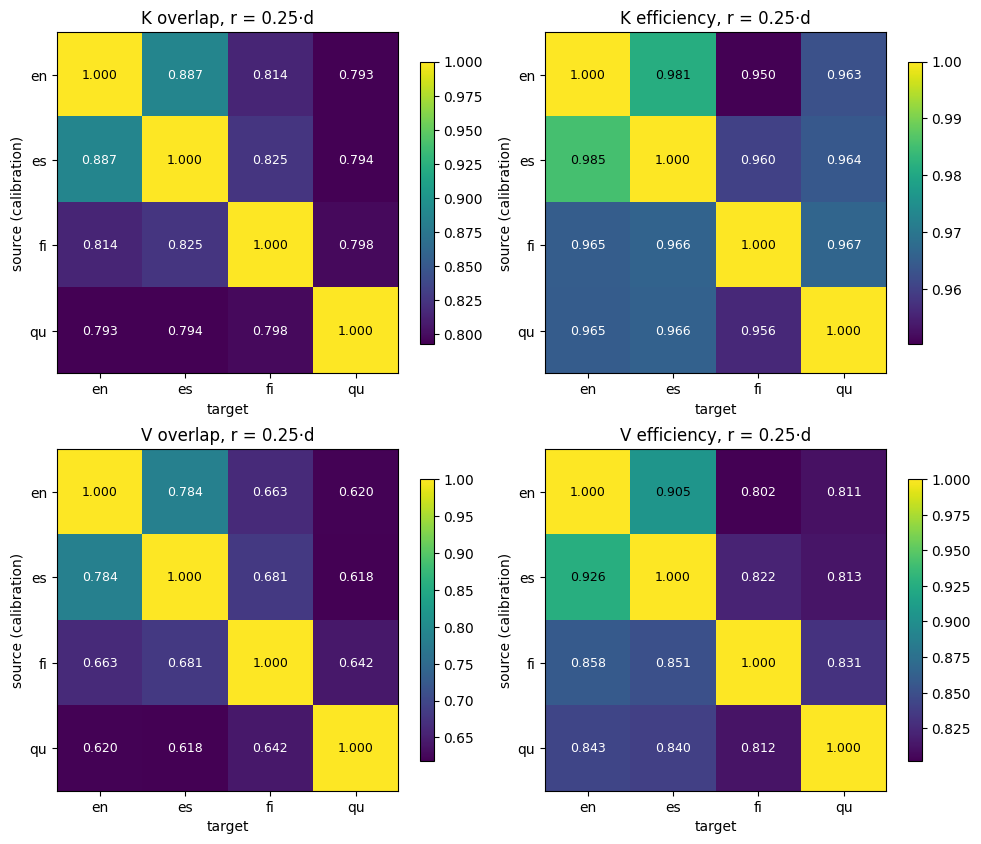

In [4]:
F = 0.25
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
for i, kind in enumerate(("K", "V")):
    for j, metric in enumerate(("overlap", "efficiency")):
        m = (heads[(heads.kind == kind) & (heads.rank_frac == F)]
             .groupby(["source", "target"])[metric].mean().unstack().reindex(index=LANGS, columns=LANGS))
        m = m.fillna(1.0)
        ax = axes[i, j]
        im = ax.imshow(m.values, cmap="viridis", vmin=m.values.min(), vmax=1)
        ax.set_xticks(range(len(LANGS)), LANGS); ax.set_yticks(range(len(LANGS)), LANGS)
        ax.set_xlabel("target"); ax.set_ylabel("source (calibration)")
        ax.set_title(f"{kind} {metric}, r = {F:g}·d")
        for (y, x), v in np.ndenumerate(m.values):
            ax.text(x, y, f"{v:.3f}", ha="center", va="center", color="w" if v < (m.values.min()+1)/2 else "k", fontsize=9)
        fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "transfer_matrices.png"), dpi=150); plt.show()

## Where does transfer from the source language break, by depth?

Week 1 found the largest quechua shift in layers 11–14 (V). If transfer efficiency also dips
there, rank level and direction move together; if it stays flat, the subspace is shared and only
the spectrum's shape changes.

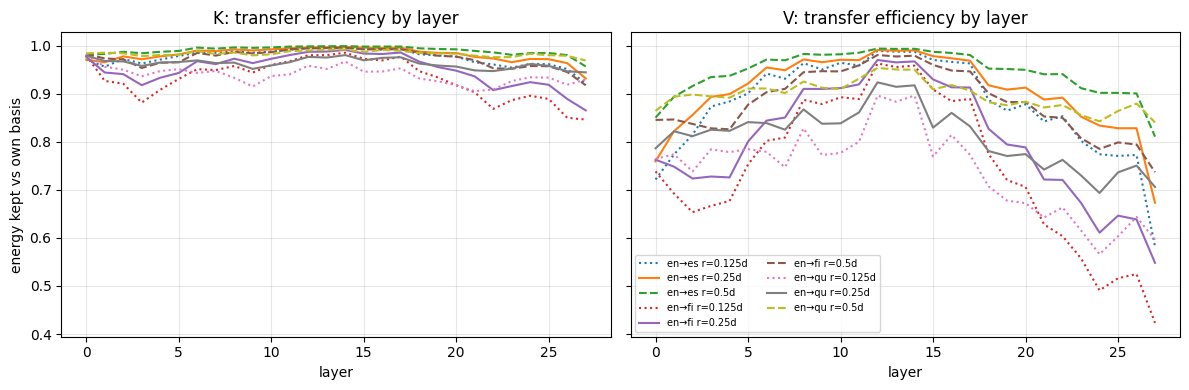

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ("K", "V")):
    for tgt in [l for l in LANGS if l != SOURCE]:
        for f, ls in zip(RANK_FRACS, (":", "-", "--")):
            y = heads[(heads.kind == kind) & (heads.source == SOURCE) & (heads.target == tgt)
                      & (heads.rank_frac == f)].groupby("layer")["efficiency"].mean()
            ax.plot(y.index, y.values, ls, label=f"{SOURCE}→{tgt} r={f:g}d")
    ax.set_title(f"{kind}: transfer efficiency by layer"); ax.set_xlabel("layer"); ax.grid(alpha=.3)
axes[0].set_ylabel("energy kept vs own basis"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "efficiency_by_layer.png"), dpi=150); plt.show()

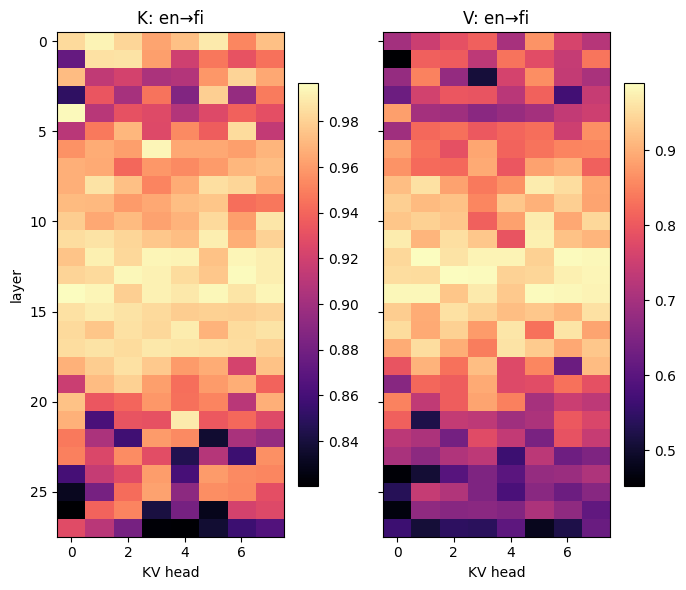

In [6]:
# per-head map of the worst-transferring target, at r = 0.25 d
others = [l for l in LANGS if l != SOURCE]
worst = (heads[(heads.source == SOURCE) & (heads.rank_frac == F)]
         .groupby("target")["efficiency"].mean().idxmin())
fig, axes = plt.subplots(1, 2, figsize=(7, 6), sharey=True)
for ax, kind in zip(axes, ("K", "V")):
    m = (heads[(heads.kind == kind) & (heads.source == SOURCE) & (heads.target == worst) & (heads.rank_frac == F)]
         .pivot(index="layer", columns="head", values="efficiency"))
    im = ax.imshow(m.values, aspect="auto", cmap="magma")
    ax.set_title(f"{kind}: {SOURCE}→{worst}"); ax.set_xlabel("KV head")
    fig.colorbar(im, ax=ax, shrink=.8)
axes[0].set_ylabel("layer")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"head_efficiency_{SOURCE}_to_{worst}.png"), dpi=150); plt.show()

In [7]:
if INCLUDE_JOINT:
    joint = res[(res.scope == "layer") & (res.rank_frac == F)]
    cmp = pd.concat({
        "per_head": heads[heads.rank_frac == F].groupby(["kind", "source", "target"])["efficiency"].mean(),
        "joint_layer": joint.groupby(["kind", "source", "target"])["efficiency"].mean()}, axis=1)
    display(cmp.round(3))   # does sharing a projection across heads make transfer better or worse?

per_head  joint_layer
kind source target                       
K    en     es         0.981        0.986
            fi         0.950        0.966
            qu         0.963        0.980
     es     en         0.985        0.990
            fi         0.960        0.970
            qu         0.964        0.982
     fi     en         0.965        0.980
            es         0.966        0.978
            qu         0.967        0.981
     qu     en         0.965        0.981
            es         0.966        0.983
            fi         0.956        0.971
V    en     es         0.905        0.940
            fi         0.802        0.881
            qu         0.811        0.912
     es     en         0.926        0.954
            fi         0.822        0.893
            qu         0.813        0.918
     fi     en         0.858        0.910
            es         0.851        0.906
            qu         0.831        0.916
     qu     en         0.843        0.909
            es         0.840        0.921
            fi         0.812        0.890

## Reading guide

| Pattern | Meaning for calibration |
|---|---|
| Overlap and efficiency both near 1 | Calibrate once in English; transfer is free. |
| Overlap low, efficiency near 1 | Languages differ only in weak directions; transfer is safe. |
| Efficiency drops at small r only | Transfer works at mild compression, breaks at aggressive compression (matches prior work on pruning and quantization). |
| Efficiency drops in specific layers | Language-aware calibration only where it matters: a cheap, targeted fix. |

**Still missing before any claim:** a noise floor. Re-run Week 1 with another seed, then compare
`en(seed 0) → en(seed 1)`. Any cross-language gap smaller than that is not a result.